In [1]:
import numpy as np
import pandas as pd
from scipy.stats import f_oneway, ttest_ind
from itertools import combinations
import scikit_posthocs as sp
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests   # для поправки Холма

In [ ]:
df = pd.read_csv("weighted_metrics_per_fold.csv")

# Задайте нужные модели (без ASSEMBLE, если хотите)
models = ['DL-CE', 'DL-DF', 'DL-WCD', 'DL-T', 'TFFM-CE', 'UN-DF', 'UN-WCD', 'ASSEMBLE']

# Фильтруем DataFrame, чтобы все дальнейшие операции были только с этими моделями
df = df[df['model'].isin(models)]

# Словари для каждой модели (можно оставить, как было)
dfs = {model: df[df['model'] == model] for model in models}
metrics = ['dice', 'iou', 'precision', 'recall']

# Словари для каждой метрики
ious = {model: df['iou'] for model, df in dfs.items()}
dices = {model: df['dice'] for model, df in dfs.items()}
recalls = {model: df['recall'] for model, df in dfs.items()}
precisions = {model: df['precision'] for model, df in dfs.items()}

In [3]:
print("===== ANOVA (глобальные тесты) =====")
for metric, data_dict in zip(metrics, [dices, ious, recalls, precisions]):
    f_stat, p_val = f_oneway(*[data_dict[m] for m in models])
    print(f"{metric}: p-value = {p_val:.6f} -> {'Модели различаются' if p_val < 0.05 else 'Разница не значима'}")


===== ANOVA (глобальные тесты) =====
dice: p-value = 0.000000 -> Модели различаются
iou: p-value = 0.000000 -> Модели различаются
precision: p-value = 0.000000 -> Модели различаются
recall: p-value = 0.000000 -> Модели различаются


In [4]:
t_test_results = []  # (metric, m1, m2, p_raw)
for metric, data_dict in zip(metrics, [dices, ious, recalls, precisions]):
    for m1, m2 in combinations(models, 2):
        t, p = ttest_ind(data_dict[m1], data_dict[m2])
        t_test_results.append((metric, m1, m2, p))

raw_p_ttest = [item[3] for item in t_test_results]
reject_ttest, p_corr_ttest, _, _ = multipletests(raw_p_ttest, alpha=0.05, method='holm')

print("\n===== Попарные t-тесты (с поправкой Холма) =====")
for (metric, m1, m2, p_raw), p_corr, rej in zip(t_test_results, p_corr_ttest, reject_ttest):
    print(f"{metric}: {m1} vs {m2} | исходное p = {p_raw:.6f} -> скорр. p = {p_corr:.6f} | значимо? {rej}")



===== Попарные t-тесты (с поправкой Холма) =====
dice: DL-CE vs DL-DF | исходное p = 0.000138 -> скорр. p = 0.007988 | значимо? True
dice: DL-CE vs DL-WCD | исходное p = 0.642508 -> скорр. p = 1.000000 | значимо? False
dice: DL-CE vs DL-T | исходное p = 0.276352 -> скорр. p = 1.000000 | значимо? False
dice: DL-CE vs TFFM-CE | исходное p = 0.000020 -> скорр. p = 0.001506 | значимо? True
dice: DL-CE vs UN-DF | исходное p = 0.000056 -> скорр. p = 0.003723 | значимо? True
dice: DL-CE vs UN-WCD | исходное p = 0.000004 -> скорр. p = 0.000310 | значимо? True
dice: DL-DF vs DL-WCD | исходное p = 0.003206 -> скорр. p = 0.096192 | значимо? False
dice: DL-DF vs DL-T | исходное p = 0.008199 -> скорр. p = 0.204986 | значимо? False
dice: DL-DF vs TFFM-CE | исходное p = 0.000117 -> скорр. p = 0.007052 | значимо? True
dice: DL-DF vs UN-DF | исходное p = 0.000362 -> скорр. p = 0.016644 | значимо? True
dice: DL-DF vs UN-WCD | исходное p = 0.000011 -> скорр. p = 0.000837 | значимо? True
dice: DL-WCD vs 

In [5]:
avg_ranks = {}
for metric in metrics:
    df[f'{metric}_rank_pct'] = df.groupby('fold')[metric].rank(pct=True)
    avg_ranks[metric] = df.groupby('model')[f'{metric}_rank_pct'].mean().sort_values(ascending=False)

In [6]:
datas = {
    metric: df.pivot(index='fold', columns='model', values=metric)
    for metric in metrics
}

test_results = {}
for metric in metrics:
    test_results[metric] = sp.posthoc_conover_friedman(
        datas[metric][models],
        melted=False,
    )

In [7]:
posthoc_pairs = []  # (metric, i, j, p_raw)
for metric in metrics:
    mat = test_results[metric]
    n = mat.shape[0]
    for i in range(n):
        for j in range(i+1, n):
            posthoc_pairs.append((metric, i, j, mat.iloc[i, j]))

raw_p_posthoc = [item[3] for item in posthoc_pairs]
reject_posthoc, p_corr_posthoc, _, _ = multipletests(raw_p_posthoc, alpha=0.05, method='holm')

# Создаём новые матрицы со скорректированными p-значениями
test_results_holm = {}
for metric in metrics:
    n = len(models)
    corr_mat = pd.DataFrame(np.ones((n, n)), index=models, columns=models, dtype=float)
    for (met, i, j, _), p_corr in zip(posthoc_pairs, p_corr_posthoc):
        if met == metric:
            corr_mat.iloc[i, j] = p_corr
            corr_mat.iloc[j, i] = p_corr
    test_results_holm[metric] = corr_mat


Тепловая карта для dice (скорректированные p-values)


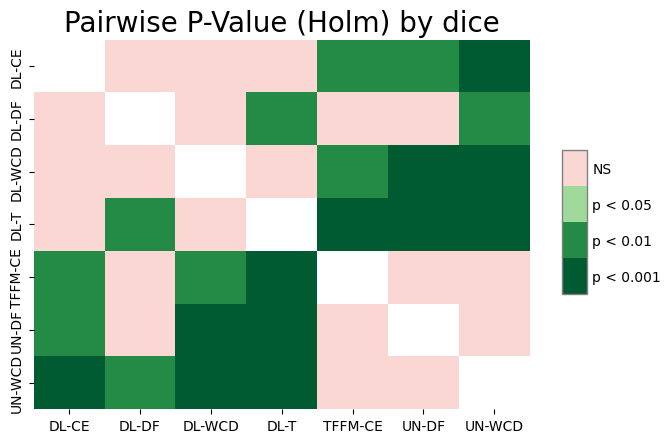


Тепловая карта для iou (скорректированные p-values)


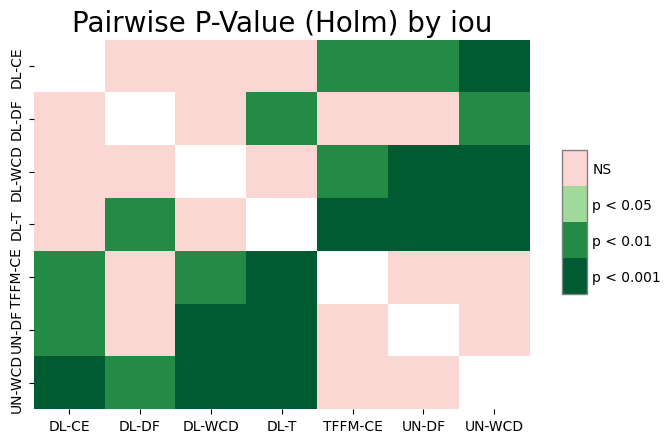


Тепловая карта для precision (скорректированные p-values)


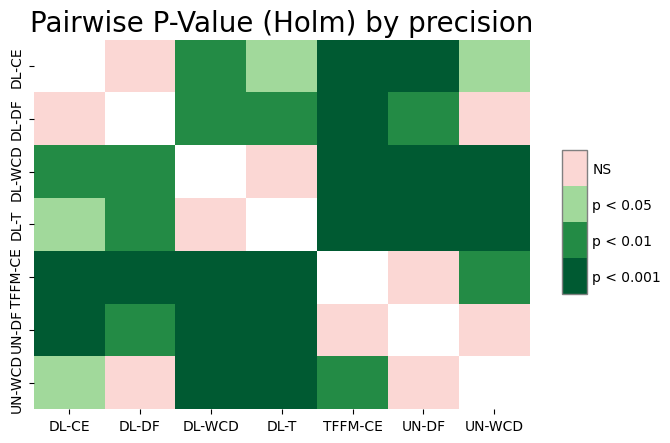


Тепловая карта для recall (скорректированные p-values)


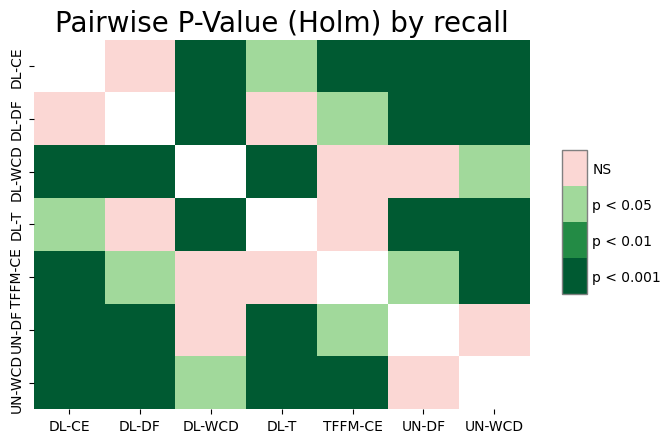

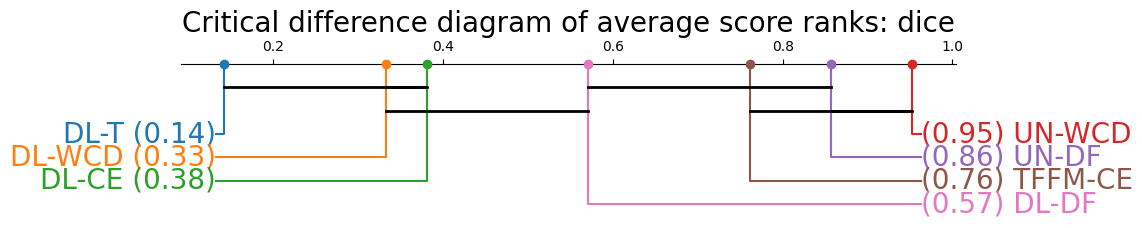

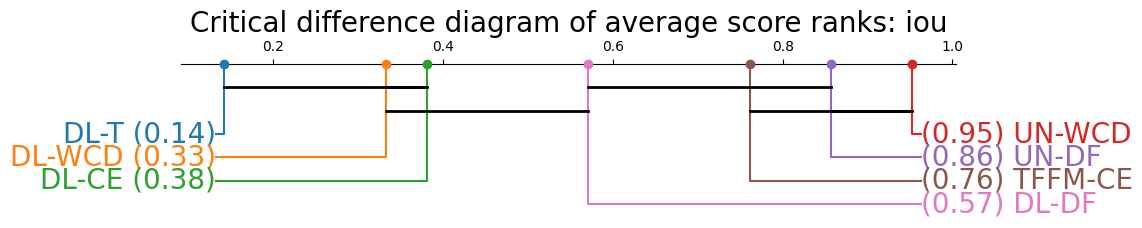

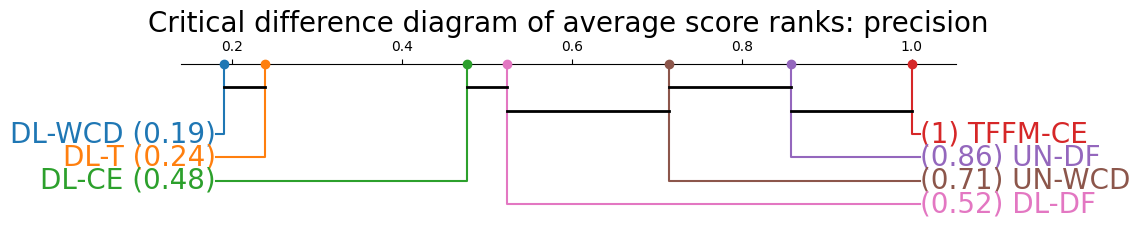

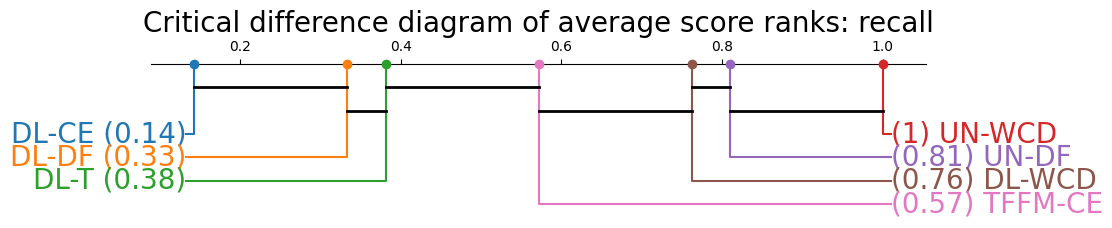

In [8]:
for metric in metrics:
    print(f"\nТепловая карта для {metric} (скорректированные p-values)")
    ax = sp.sign_plot(test_results_holm[metric])[0]
    ax.set_title(f'Pairwise P-Value (Holm) by {metric}', fontdict={'size': 20})
    plt.show()

for metric in metrics:
    plt.figure(figsize=(10, 2), dpi=100)
    plt.title(f'Critical difference diagram of average score ranks: {metric}', fontdict={'size': 20})
    sp.critical_difference_diagram(
        avg_ranks[metric],
        test_results_holm[metric],
        label_props={'size': 20}
    )
    plt.show()